# 01 — Data cleaning & exploratory analysis

**Project:** Stochastic modelling of air-pollution exceedance events in Delhi
**Part:** Member A — data pipeline + EDA

**Source:** Central Pollution Control Board (CPCB), *CAAQMS Data Repository*,
station **R K Puram, Delhi – DPCC (site 124)**, hourly data 2011–2026,
https://airquality.cpcb.gov.in/ccr/

**Output:** `data/clean/delhi_rkpuram_daily.csv` — one row per day, used by all three members.

Pipeline:
1. Read the 18 yearly hourly files, keep PM2.5.
2. Remove physically implausible readings (analyser cap of 1000 µg/m³).
3. Aggregate to a daily mean; a day is *observed* only if ≥ 18 of 24 hours (75 %) are valid.
4. Linearly interpolate gaps of **≤ 3 consecutive days**; longer gaps stay missing.
5. Attach CPCB AQI category and IMD season.
6. Choose the study window from data coverage.

In [1]:
from pathlib import Path

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAW = Path("../data/raw")
CLEAN = Path("../data/clean")
FIG = Path("../figures")
RES = Path("../results")
for p in (CLEAN, FIG, RES):
    p.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

MIN_HOURS = 18   # minimum valid hours for a day to count as observed (75 % rule)
MAX_FILL = 3     # interpolate only gaps of at most this many consecutive days
CAP = 1000.0     # analyser upper limit; readings at the cap are censored, not real values
STUDY = ("2016-01-01", "2025-12-31")    # main estimation window (10 full years)
HOLDOUT = ("2026-01-01", "2026-09-30")  # extra out-of-sample period (partial year)

## 1. Load hourly data

In [2]:
files = sorted(RAW.glob("Raw_Data_*_1Hr.csv"))
frames = [pd.read_csv(f, usecols=["Timestamp", "PM2.5 (µg/m³)"], na_values=["NA"]) for f in files]
hourly = (pd.concat([f for f in frames if len(f)], ignore_index=True)
            .rename(columns={"PM2.5 (µg/m³)": "pm25"}))
hourly["Timestamp"] = pd.to_datetime(hourly["Timestamp"])
hourly = hourly.set_index("Timestamp").sort_index()

print(f"{len(files)} files, {len(hourly):,} hourly rows, {hourly.index.min()} -> {hourly.index.max()}")
print("duplicate timestamps:", hourly.index.duplicated().sum())
print("negative values     :", (hourly.pm25 < 0).sum())
print(f"readings at cap {CAP:.0f}:", (hourly.pm25 >= CAP).sum(),
      "(all in", sorted(hourly.index[hourly.pm25 >= CAP].year.unique()), ")")

18 files, 135,168 hourly rows, 2011-05-01 00:00:00 -> 2026-09-30 23:00:00
duplicate timestamps: 0
negative values     : 0
readings at cap 1000: 17 (all in [2011] )


In [3]:
hourly.loc[hourly.pm25 >= CAP, "pm25"] = np.nan
hourly.loc[hourly.pm25 < 0, "pm25"] = np.nan

## 2. Daily aggregation and gap filling

In [4]:
g = hourly.pm25.resample("D")
daily = pd.DataFrame({"pm25_mean_all": g.mean(), "valid_hours": g.count()})
daily["pm25_obs"] = daily.pm25_mean_all.where(daily.valid_hours >= MIN_HOURS)

miss = daily.pm25_obs.isna()
run_id = (miss != miss.shift()).cumsum()
run_len = miss.groupby(run_id).transform("size")
fillable = miss & (run_len <= MAX_FILL)
interp = daily.pm25_obs.interpolate(method="time", limit_area="inside")

daily["pm25"] = daily.pm25_obs.where(~fillable, interp)
daily["status"] = np.select([~miss, fillable], ["observed", "interpolated"], "missing")
daily.loc[daily.pm25.isna(), "status"] = "missing"   # edge gaps that interpolation cannot reach
daily.status.value_counts()

status
observed        4066
missing         1247
interpolated     319
Name: count, dtype: int64

### Coverage by year — this decides the study window

In [5]:
cov = (pd.crosstab(daily.index.year, daily.status, normalize="index") * 100).round(1)
cov = cov.reindex(columns=["observed", "interpolated", "missing"], fill_value=0)
cov.index.name = "year"
cov["days"] = daily.groupby(daily.index.year).size()
cov

status,observed,interpolated,missing,days
year,,,,
2011,40.0,9.4,50.6,245
2012,53.0,12.3,34.7,366
2013,16.7,6.0,77.3,365
2014,0.0,0.0,100.0,365
2015,61.4,6.0,32.6,365
2016,77.3,6.3,16.4,366
2017,80.5,6.0,13.4,365
2018,94.0,4.9,1.1,365
2019,72.6,9.6,17.8,365


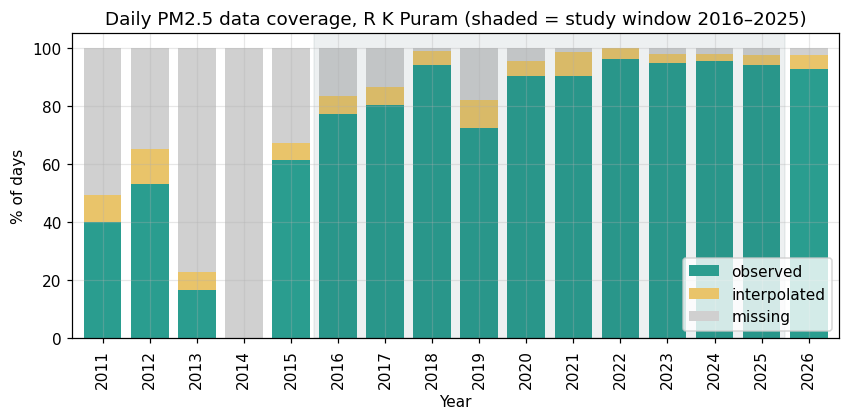

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
cov[["observed", "interpolated", "missing"]].plot.bar(
    stacked=True, ax=ax, color=["#2a9d8f", "#e9c46a", "#d0d0d0"], width=0.8)
ax.axvspan(cov.index.get_loc(2016) - 0.5, cov.index.get_loc(2025) + 0.5, color="#264653", alpha=0.08)
ax.set(title="Daily PM2.5 data coverage, R K Puram (shaded = study window 2016–2025)",
       xlabel="Year", ylabel="% of days")
ax.legend(loc="lower right", frameon=True)
fig.savefig(FIG / "A01_coverage_by_year.png")
plt.show()

**Decision.** 2011–2015 are unusable as a continuous series (2014 is completely empty, 2013 is 17 % covered,
2015 starts only in April). From **2016 to 2025** every year has ≥ 72 % observed days, and 2018–2025 are ≥ 90 %.
We therefore estimate on **2016-01-01 → 2025-12-31** (10 full years) and keep **Jan–Sep 2026** as an extra hold-out period.

## 3. AQI category and season

In [7]:
AQI_BINS = [-np.inf, 30, 60, 90, 120, 250, np.inf]
AQI_LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
          6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}

clean = daily.loc[STUDY[0]:HOLDOUT[1], ["pm25", "status", "valid_hours"]].copy()
clean["pm25"] = clean.pm25.round(2)
clean["aqi_category"] = pd.cut(clean.pm25, AQI_BINS, labels=AQI_LABELS)
clean["year"] = clean.index.year
clean["month"] = clean.index.month
clean["season"] = clean.month.map(SEASON)
clean["period"] = np.where(clean.index <= STUDY[1], "study", "holdout")
clean.index.name = "date"
clean.to_csv(CLEAN / "delhi_rkpuram_daily.csv")
print(f"saved {len(clean)} days to {CLEAN / 'delhi_rkpuram_daily.csv'}")
clean.head()

saved 3926 days to ..\data\clean\delhi_rkpuram_daily.csv


,pm25,status,valid_hours,aqi_category,year,month,season,period
date,,,,,,,,
2016-01-01,411.87,observed,24,Severe,2016,1,Winter,study
2016-01-02,288.18,observed,24,Severe,2016,1,Winter,study
2016-01-03,392.96,observed,24,Severe,2016,1,Winter,study
2016-01-04,446.64,observed,19,Severe,2016,1,Winter,study
2016-01-05,338.33,observed,23,Severe,2016,1,Winter,study


In [8]:
study = clean.loc[STUDY[0]:STUDY[1]]
valid = study[study.status != "missing"]
print(f"Study window: {len(study)} days | observed {(study.status == 'observed').sum()} | "
      f"interpolated {(study.status == 'interpolated').sum()} | missing {(study.status == 'missing').sum()}")
valid.pm25.describe().round(1)

Study window: 3653 days | observed 3236 | interpolated 194 | missing 223


count    3430.0
mean      111.9
std        89.0
min         1.2
25%        46.6
50%        83.9
75%       154.5
max       729.3
Name: pm25, dtype: float64

## 4. Exploratory analysis

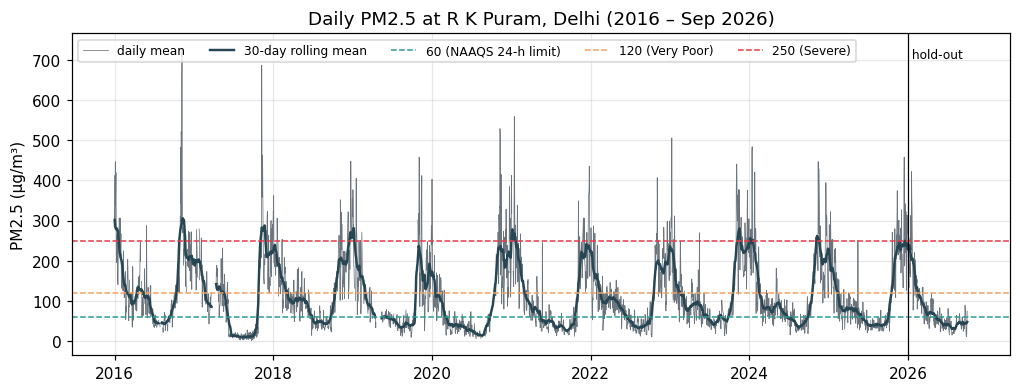

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
s = clean.pm25
ax.plot(s.index, s, lw=0.5, color="#6c757d", label="daily mean")
ax.plot(s.index, s.rolling(30, min_periods=15, center=True).mean(), lw=1.6, color="#264653", label="30-day rolling mean")
for y, c, lab in [(60, "#2a9d8f", "60 (NAAQS 24-h limit)"), (120, "#f4a261", "120 (Very Poor)"), (250, "#e63946", "250 (Severe)")]:
    ax.axhline(y, color=c, ls="--", lw=1, label=lab)
ax.axvline(pd.Timestamp(HOLDOUT[0]), color="k", lw=0.8)
ax.text(pd.Timestamp(HOLDOUT[0]), ax.get_ylim()[1] * 0.92, " hold-out", fontsize=8)
ax.set(title="Daily PM2.5 at R K Puram, Delhi (2016 – Sep 2026)", ylabel="PM2.5 (µg/m³)", xlabel="")
ax.legend(ncol=5, fontsize=8, loc="upper left")
fig.savefig(FIG / "A02_timeseries.png")
plt.show()

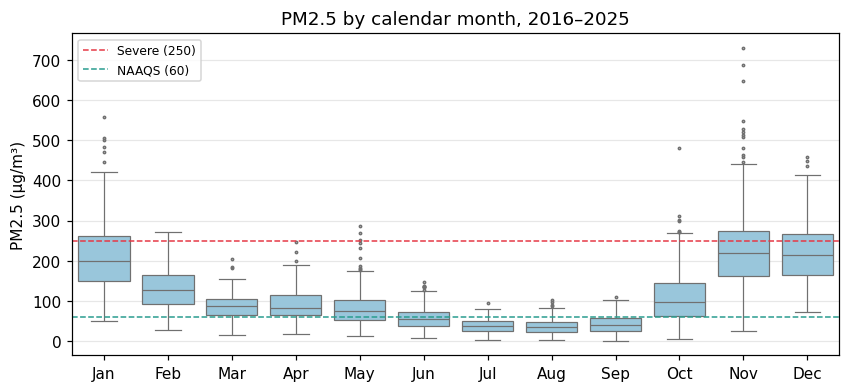

In [10]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=valid, x="month", y="pm25", ax=ax, color="#8ecae6", fliersize=1.5, linewidth=0.8)
ax.axhline(250, color="#e63946", ls="--", lw=1, label="Severe (250)")
ax.axhline(60, color="#2a9d8f", ls="--", lw=1, label="NAAQS (60)")
ax.set_xticks(range(12), month_names)
ax.set(title="PM2.5 by calendar month, 2016–2025", xlabel="", ylabel="PM2.5 (µg/m³)")
ax.legend(fontsize=8)
fig.savefig(FIG / "A03_monthly_boxplot.png")
plt.show()

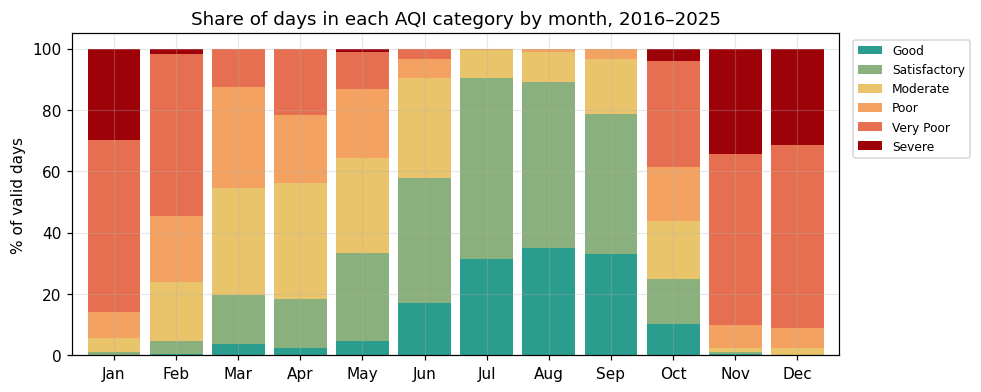

In [11]:
cat_month = pd.crosstab(valid.month, valid.aqi_category, normalize="index") * 100
colors = ["#2a9d8f", "#8ab17d", "#e9c46a", "#f4a261", "#e76f51", "#9d0208"]
fig, ax = plt.subplots(figsize=(9, 3.8))
cat_month.plot.bar(stacked=True, ax=ax, color=colors, width=0.85)
ax.set_xticks(range(12), month_names, rotation=0)
ax.set(title="Share of days in each AQI category by month, 2016–2025", xlabel="", ylabel="% of valid days")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.savefig(FIG / "A04_category_by_month.png")
plt.show()

In [12]:
cat_table = valid.aqi_category.value_counts().reindex(AQI_LABELS).to_frame("days")
cat_table["% of days"] = (cat_table.days / cat_table.days.sum() * 100).round(1)
cat_table

,days,% of days
aqi_category,,
Good,397,11.6
Satisfactory,802,23.4
Moderate,620,18.1
Poor,425,12.4
Very Poor,886,25.8
Severe,300,8.7


## 5. Choosing the event threshold

An *exceedance event* is a day whose mean PM2.5 is above a threshold *c*. For a Poisson model the events
should be reasonably **rare**. The table compares candidate thresholds.
An *episode* is a run of consecutive exceedance days.

In [13]:
def episodes(flag: pd.Series) -> pd.Series:
    """Lengths of runs of consecutive True values in a daily boolean series (gaps break runs)."""
    flag = flag.asfreq("D", fill_value=False)
    rid = (flag != flag.shift()).cumsum()
    return flag.groupby(rid).sum()[flag.groupby(rid).first()]

rows = []
n_years = len(study) / 365.25
for c in [60, 90, 120, 250]:
    ev = valid.pm25 > c
    ep = episodes(ev.reindex(study.index, fill_value=False))
    rows.append({"threshold": c, "event days": int(ev.sum()), "% of valid days": round(ev.mean() * 100, 1),
                 "per year": round(ev.sum() / n_years, 1), "episodes": len(ep),
                 "mean episode length (days)": round(ep.mean(), 2)})
thr = pd.DataFrame(rows).set_index("threshold")
thr

,event days,% of valid days,per year,episodes,mean episode length (days)
threshold,,,,,
60,2231,65.0,223.1,185,12.06
90,1611,47.0,161.1,186,8.66
120,1186,34.6,118.6,160,7.41
250,300,8.7,30.0,112,2.68


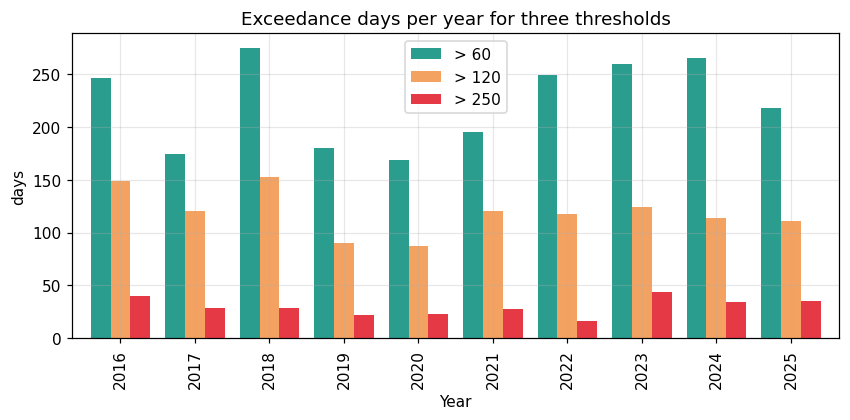

In [14]:
yearly = pd.DataFrame({f"> {c}": (valid.pm25 > c).groupby(valid.year).sum() for c in [60, 120, 250]})
fig, ax = plt.subplots(figsize=(9, 3.6))
yearly.plot.bar(ax=ax, color=["#2a9d8f", "#f4a261", "#e63946"], width=0.8)
ax.set(title="Exceedance days per year for three thresholds", xlabel="Year", ylabel="days")
fig.savefig(FIG / "A05_exceedances_per_year.png")
plt.show()

**Decision: threshold c = 250 µg/m³ (CPCB "Severe").**
* Above 60 µg/m³ more than half of all days exceed — that is the normal state, not a rare event.
* Above 120 µg/m³ about one day in three exceeds — still too frequent for a rare-event (Poisson) model.
* Above 250 µg/m³ about 9 % of days exceed (300 days in 10 years, 30 per year). That is rare enough for a Poisson model,
  and it matches the public-health definition of a "Severe" air-quality day.

Threshold 120 is kept as a sensitivity check in notebook 02.

In [15]:
summary = {
    "station": "R K Puram, Delhi - DPCC (CPCB site 124)",
    "hourly_rows": int(len(hourly)),
    "study_window": list(STUDY), "holdout_window": list(HOLDOUT),
    "study_days": int(len(study)),
    "study_observed": int((study.status == "observed").sum()),
    "study_interpolated": int((study.status == "interpolated").sum()),
    "study_missing": int((study.status == "missing").sum()),
    "pm25_mean": round(float(valid.pm25.mean()), 1), "pm25_median": round(float(valid.pm25.median()), 1),
    "pm25_max": round(float(valid.pm25.max()), 1),
    "coverage_by_year": cov.reset_index().to_dict("records"),
    "category_table": cat_table.reset_index().to_dict("records"),
    "threshold_table": thr.reset_index().to_dict("records"),
}
(RES / "A01_data_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("saved results/A01_data_summary.json")

saved results/A01_data_summary.json
